## Phase Diagram

This assumes the data for the phase diagram was generated on a cluster or similar compute.
An example of a bash script that can be run on a cluster to generate data can be found at root/models/model_pet_nmda/scripts/G_alpha_sweep.sh and root/models/model_pet_nmda/scripts/G_alpha_sweep.py. The way it is run varies by system so it should be carefully changed in each circumstance.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.colors import LinearSegmentedColormap
# plt.style.use(['science', 'nature'])

plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.title_fontsize": 16,
    "legend.fontsize": 13,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)

cmaps_phase = {
    "pop_A": LinearSegmentedColormap.from_list(
        "pop_A", ["#ffffff", "#8fedbd", "#188b4e"], N=256
    ),
    "pop_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#ffffff", "#ffd4de", "#eaa8b7"], N=256
    ),
    "pop_A_minus_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#eaa8b7", "#ffffff", "#188b4e"], N=256
    ),
}

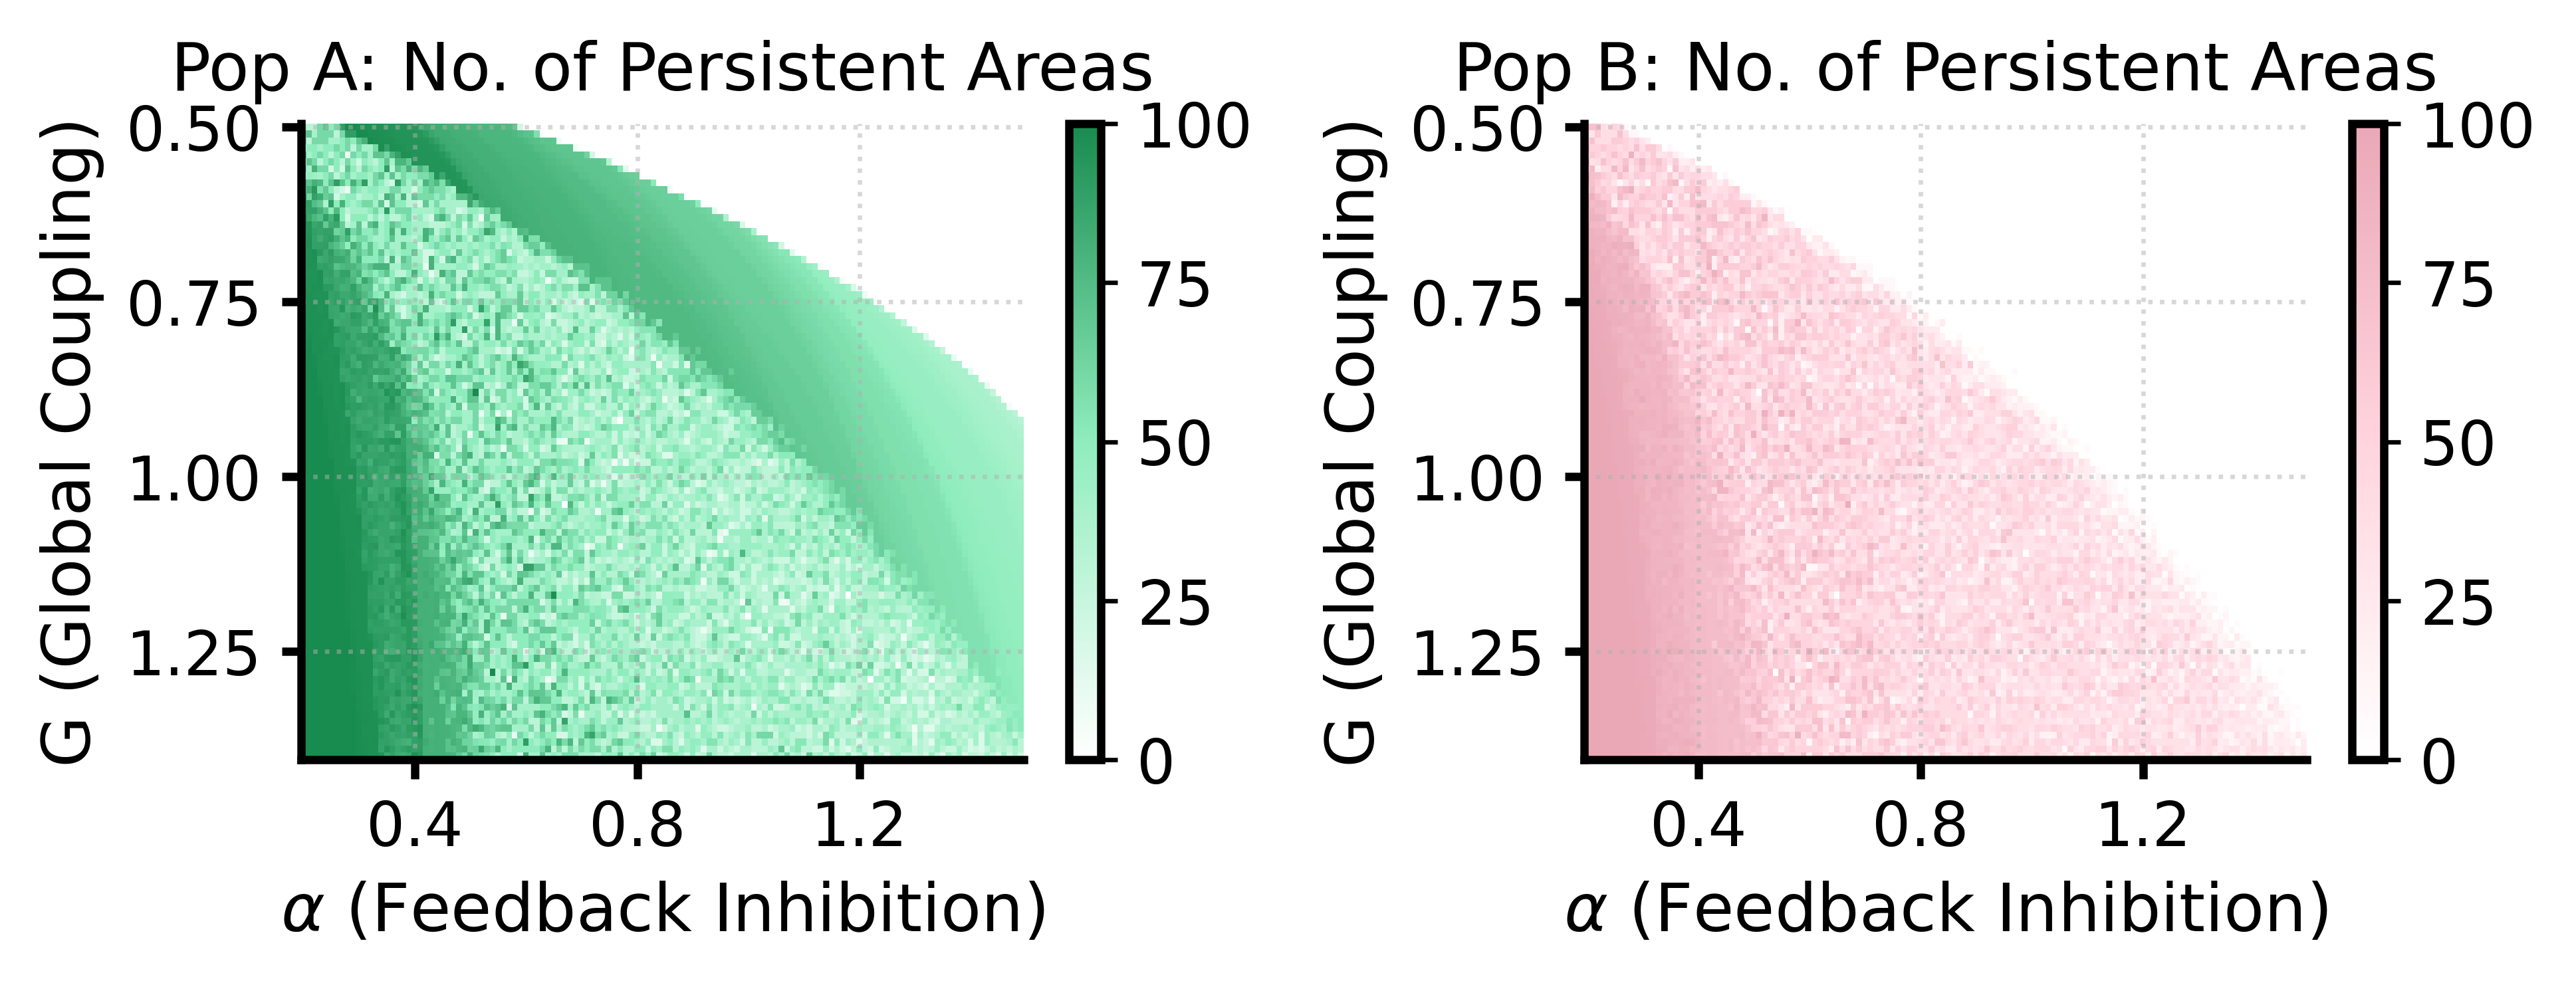

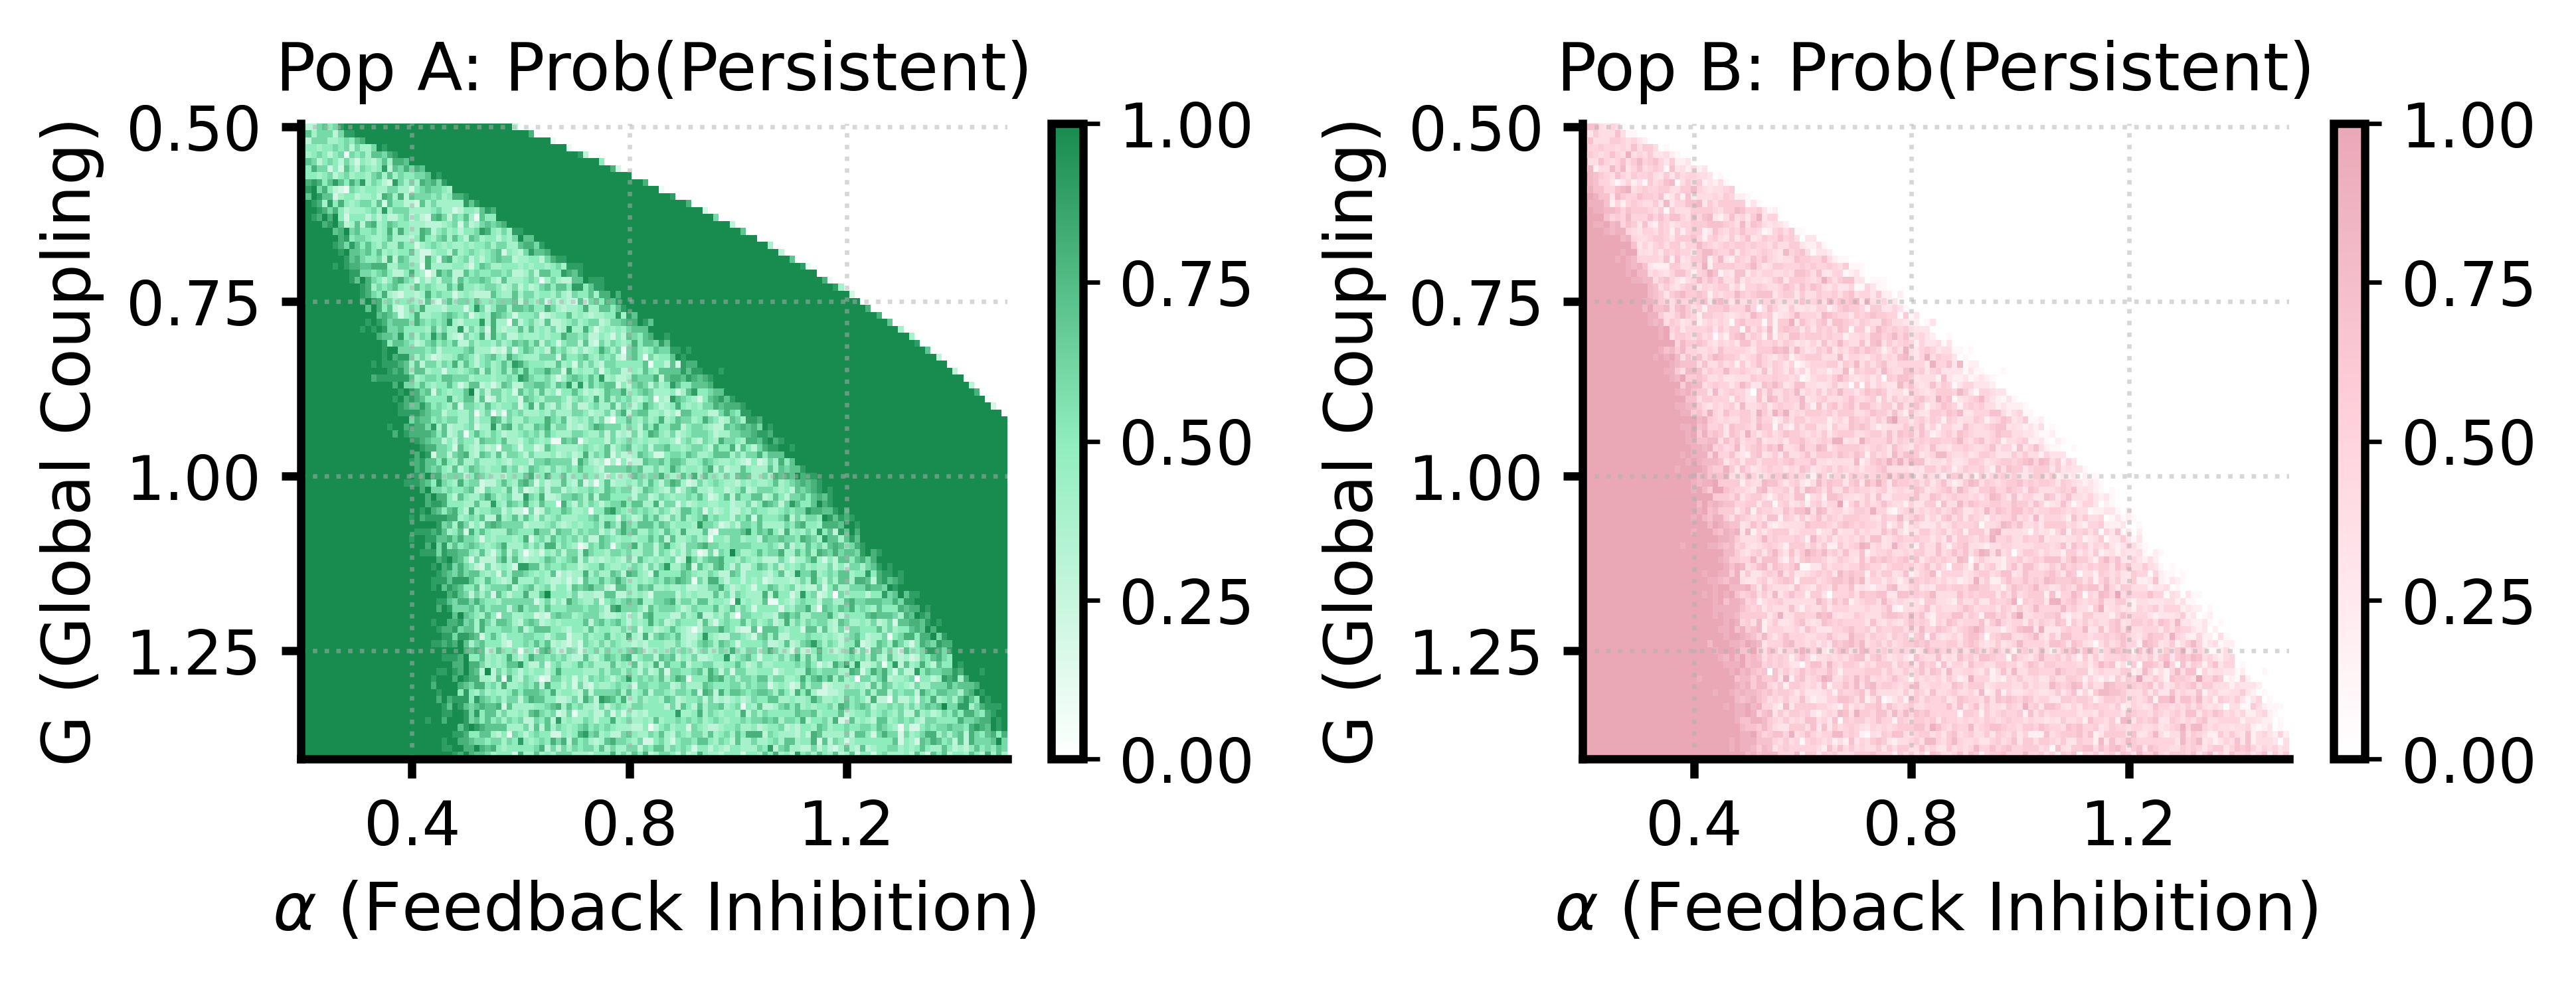

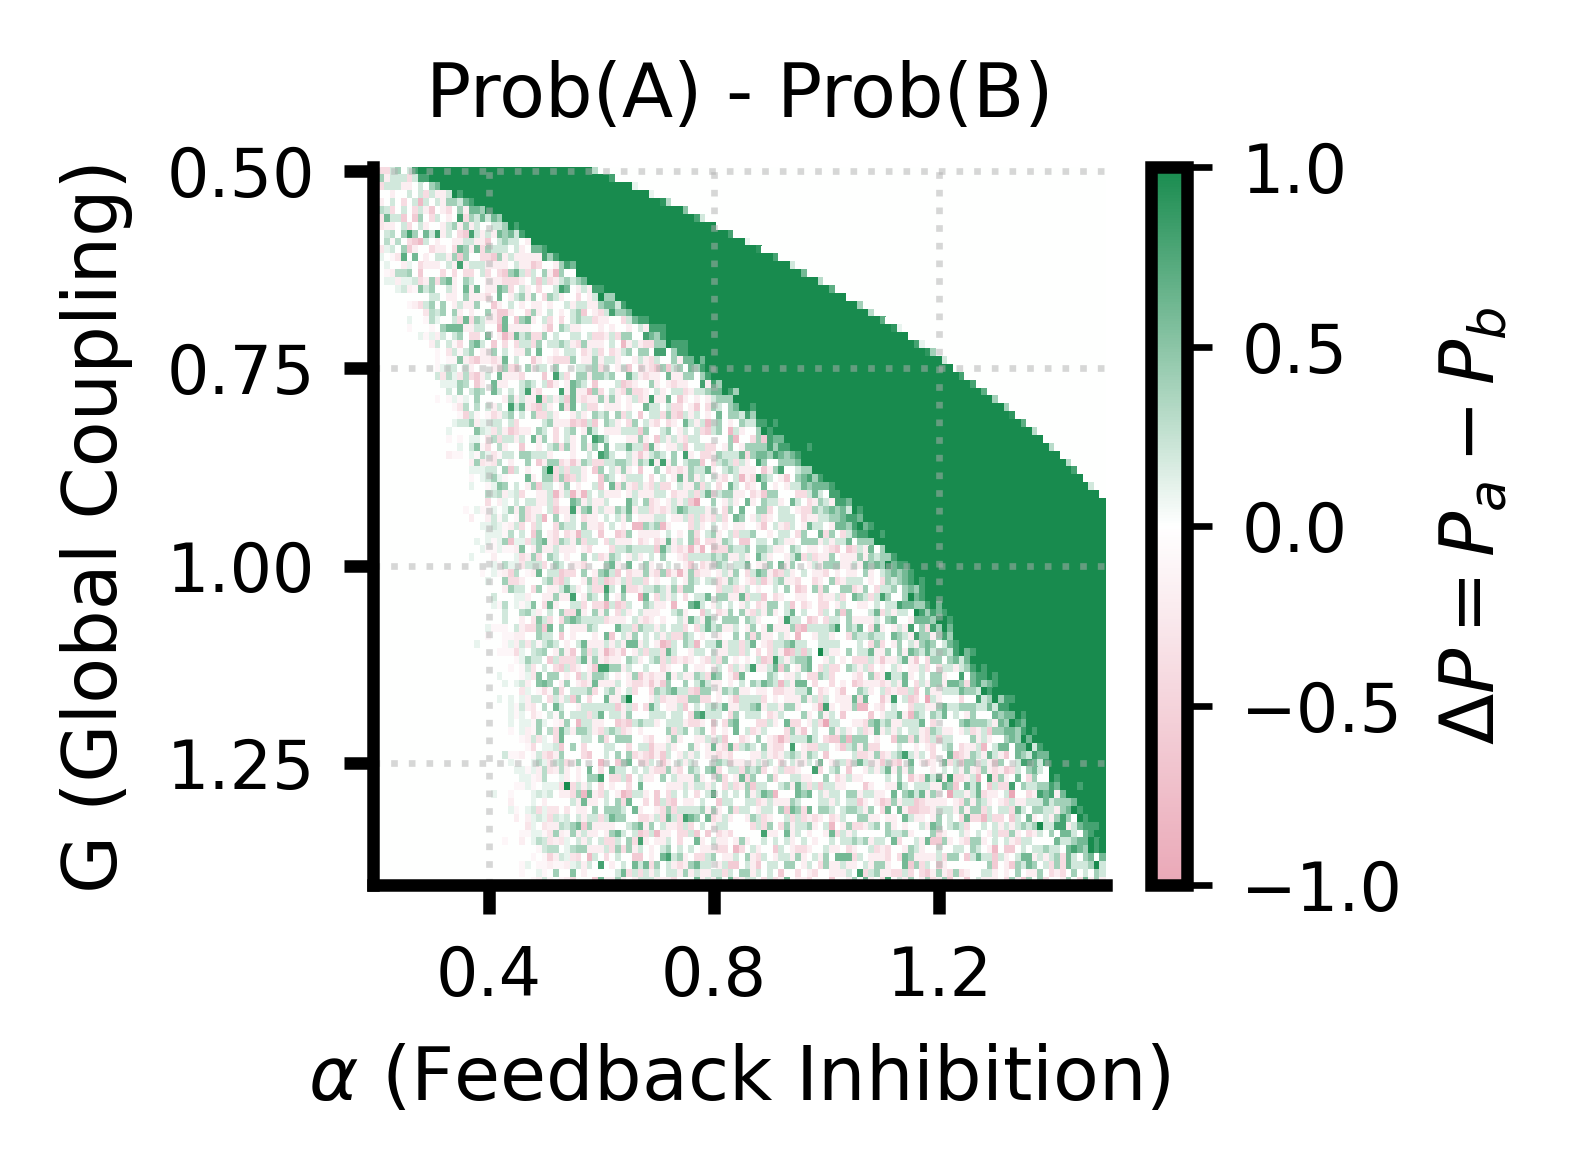

All plots generated and saved in: saved_plots/Figure_4


In [2]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

def plot_forbidden_gap_analysis():
    csv_path = '../models/model_pet_nmda/results/phase_diagram_G_alpha/g_alpha_random_seeds_per_G_alpha_corrected_spont_fun/persistent_activity_stats_all_runs.csv'
    results_dir = 'saved_plots/Figure_4'
    df = pd.read_csv(csv_path, delimiter=",", skipinitialspace=True)
    df = df[df['G'] <= 1.4] # Simulation didn't work for some values above this

    col_g = "G"
    col_alpha = "alpha"
    col_no_persist = "Prob_NoPersist"
    col_a_only = "Prob_A_Only"
    col_b_only = "Prob_B_Only"
    col_a_b = "Prob_A_B"
    col_mean_a = "MeanAreasA_uncond"
    col_mean_b = "MeanAreasB_uncond"

    from matplotlib.ticker import MaxNLocator

    def style_ax(ax, nbins=4):
        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(nbins))
        ax.yaxis.set_major_locator(MaxNLocator(nbins))
        ax.grid(which='major', linestyle=':', alpha=0.5)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.tick_params(top=False, right=False)

    def style_cbar(cbar, nbins=4):
        cbar.locator = MaxNLocator(nbins)
        cbar.update_ticks()
        cbar.ax.minorticks_off()
        cbar.ax.tick_params(which='both', direction='out', length=3, width=0.8)

    # Mean Number of Areas for A and B
    piv_mean_a = df.pivot(index=col_g, columns=col_alpha, values=col_mean_a)
    piv_mean_b = df.pivot(index=col_g, columns=col_alpha, values=col_mean_b)

    plt.figure(figsize=(6.6, 2.6))

    # Mean Areas A
    plt.subplot(1, 2, 1)
    plt.title("Pop A: No. of Persistent Areas")
    imA = plt.pcolor(
        piv_mean_a.columns,
        piv_mean_a.index,
        piv_mean_a.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imA, ax=ax)
    style_cbar(cbar, nbins=4)

    # Mean Areas B
    plt.subplot(1, 2, 2)
    plt.title("Pop B: No. of Persistent Areas")
    imB = plt.pcolor(
        piv_mean_b.columns,
        piv_mean_b.index,
        piv_mean_b.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imB, ax=ax)
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "mean_areas_AB.pdf"))
    plt.show()

    # Probability(A) & Probability(B), plus difference
    # Probability(A) = Probability(A Only) + Probability(A & B)
    # Probability(B) = Probability(B Only) + Probability(A & B)

    df["Probability(A)"] = df[col_a_only] + df[col_a_b]
    df["Probability(B)"] = df[col_b_only] + df[col_a_b]
    df["ProbDiff(A-B)"] = df["Probability(A)"] - df["Probability(B)"]

    piv_probA = df.pivot(index=col_g, columns=col_alpha, values="Probability(A)")
    piv_probB = df.pivot(index=col_g, columns=col_alpha, values="Probability(B)")
    piv_probDiff = df.pivot(index=col_g, columns=col_alpha, values="ProbDiff(A-B)")

    # Plot Probability(A) and Probability(B) side by side
    plt.figure(figsize=(6.6, 2.6))

    # Probability(A)
    plt.subplot(1, 2, 1)
    plt.title("Pop A: Prob(Persistent)")
    imA = plt.pcolor(
        piv_probA.columns,
        piv_probA.index,
        piv_probA.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imA, ax=ax)
    style_cbar(cbar, nbins=4)

    # Probability(B)
    plt.subplot(1, 2, 2)
    plt.title("Pop B: Prob(Persistent)")
    imB = plt.pcolor(
        piv_probB.columns,
        piv_probB.index,
        piv_probB.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imB, ax=ax)
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "prob_A_vs_prob_B.pdf"))
    plt.show()

    # Plot Probability(A)-Probability(B)
    mpl.rcParams.update({
        "font.size": 8,
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
    })
    plt.figure(figsize=(2.6, 2))
    plt.title("Prob(A) - Prob(B)")
    imDiff = plt.pcolor(
        piv_probDiff.columns,
        piv_probDiff.index,
        piv_probDiff.values,
        cmap=cmaps_phase['pop_A_minus_B'],
        shading='auto'
    )
    ax = plt.gca()
    ax.invert_yaxis()
    plt.xlabel("$\\alpha$ (Feedback Inhibition)")
    plt.ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = plt.colorbar(imDiff, ax=ax)
    cbar.set_label(r'$\Delta P = P_a - P_b$')
    style_cbar(cbar, nbins=4)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "prob_diff_A_minus_B.pdf"))
    plt.show()

    print("All plots generated and saved in:", results_dir)

if __name__ == "__main__":
    plot_forbidden_gap_analysis()


## Under, Over, Mid and Optimal simulation traces generator

In [17]:
# Script that runs simulation at G-alpha combinations that results in under-activity or over-activity
# Outputs delay firing rates for brain maps
# Uncomment the one that you want to use and comment the other one when declaring g and alpha
import os
import sys
import numpy as np

# Add the project root to the Python PATH
script_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(script_dir, '../models/model_pet_nmda'))
sys.path.append(project_root)

from src.data import load_and_preprocess_data as get_data
from src.models import WorkingMemoryNetwork
from config.WM_params import WorkingMemoryParameters
import time
np.set_printoptions(threshold=np.inf)

random_seed = 666
outside_rng = np.random.default_rng(random_seed)

experiment = 'mid_active_random'  # or under_active or mid_active_random or over_active

if experiment == 'over_active':
    g = 1.3
    alpha = 0.25
elif experiment == 'under_active':
    g = 0.6
    alpha = 1.4
elif experiment == 'mid_active_random':
    g = 1.0
    alpha = 0.6
elif experiment == 'normal':
    g = 0.83
    alpha = 1.34
data = get_data(data_folder_path='../data/processed', parcellation='schaefer200')
area_names = data['area_names']
SLN = data['SLN']
W = data['W']
h = data['hier_vals']
normalized_nmda_rd = data['nmda_rd']

# Initial condition and parameters
N = len(area_names)
Y0 = np.zeros((N, 8))
Y0[:, 0:3] = 5 * (1 + np.tanh(outside_rng.normal(0, 2, (N, 3)))) # r values are initialized randomly between 0 and 10
WM_params = WorkingMemoryParameters()
WM_params.update(G=g, ALPHA=alpha, J_MAX=0.3) # Update G and alpha to optimal settings
# Generate the network
WM_network = WorkingMemoryNetwork(area_names=area_names, Y0=Y0, W=W, F=SLN, h=h,
                                  normalized_nmda_rd=normalized_nmda_rd,
                                  params=WM_params, gradient='NMDA')
# Run the simulation
t_end = 7
dt = 0.5e-3
stim_start_time = 2
stim_duration = 0.5
t_eval = np.arange(0, t_end+dt, dt) # Time points of the simulation
I_ext_strength = np.zeros((N, 3))

# Target names for which we want to assign 0.3
target_names = ['Vis_5', 'Vis_7', 'Vis_9']
target_names_distractor = ['Vis_5', 'Vis_7', 'Vis_9']
# Find indexes of the target names in the list
rows = np.where(np.isin(area_names, target_names))[0]
rows_distractor = np.where(np.isin(area_names, target_names_distractor))[0]
I_ext_strength[rows, 0] = 0.3

start = time.perf_counter()
state_history, input_history = WM_network.run(t_end=t_end, dt=dt, I_ext_strengths=np.stack([I_ext_strength]),
                               ts_ext_start=np.array([stim_start_time]),
                               ts_ext_end=np.array([stim_start_time + stim_duration]))
end = time.perf_counter()
print("Elapsed (after compilation) = {}s".format((end - start)))

avg_firing_rates_A, avg_firing_rates_B = WM_network.save_avg_firing_rates_last_two_seconds(variables=['r_A', 'r_B'])
state_history_extract = WM_network.get_state_histories(['r_A'])[-1]
avg_firing_rates = WM_network.save_avg_firing_rates_last_two_seconds()
if g == 0.6 and alpha == 1.4:
    np.save('saved_plots/Figure_4/delay_FR_G06_alpha14.npy', avg_firing_rates)
    print('saved')
elif g == 1.3 and alpha == 0.25:
    np.save('saved_plots/Figure_4/delay_FR_G13_alpha025.npy', avg_firing_rates)

_, pops = WM_network.check_sustained_activity_after_stim_removal()

# Need condition to check if it's A or B there, right now r_B is at index 0, it gets pops_A as pops_B.
try:
    pops_A = pops[0][1]
except:
    pops_A = []
try:
    pops_B = pops[1][1]
except:
    pops_B = []

print('Nodes where population B is persistent:', pops_B)
spont_switch, pop_switch = WM_network.check_spontaneous_switch_to_high_state(stim_start_time)
print(f'There is spontaneous switch to higher state: {spont_switch}, in populations {pop_switch}')
changes_detected, changed_populations = WM_network.check_sustained_activity_after_stim_removal()
print(changed_populations)
try:
    print('Number of persistent areas:', len(changed_populations[0][1]))
except:
    print('No persistent areas')
    
area_names_for_figure = ['Area 46']
_ = WM_network.plot_n_areas(xlim=(-2, t_end - 2), ylim=(-5, 85),
                            target_area_names=['SalVentAttn_PFCl_1'],
                            names_for_figures=area_names_for_figure,
                            variables=['r_A', 'r_B'], colors=['#56c68a', '#eaa8b7'],
                            save_path=f'saved_plots/Figure_4/{experiment}_persistent_activity.svg',
                            legend=False,
                            show=False)

Elapsed (after compilation) = 0.49721036601113155s
Nodes where population B is persistent: []
There is spontaneous switch to higher state: True, in populations [('r_A', [90, 92]), ('r_B', [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99])]
[('r_B', [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99])]
Number of persistent areas: 97


## Brain plots for Over and Under active (R1 and R4)

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from nilearn import datasets, plotting
from nibabel.freesurfer.io import read_annot
import nibabel.freesurfer as fs
from matplotlib.colors import LinearSegmentedColormap
cmaps = {
    "excitation_seq": LinearSegmentedColormap.from_list(
        "exc_seq", ["#e7f6ed", "#86c3a2", "#56c68a"], N=256
    )
}
def plot_multiple_surfaces(
    file_paths,
    annot_file_path,
    cmap=cmaps['excitation_seq'],
    save_dir=None,
    views=('lateral', 'medial'),
    dpi=1200,
    figsize=(6, 6),
    symmetric_cbar=False,
):
    """
    Plot surface stat maps for multiple datasets, with 'over_active' on its own color scale
    and the other two sharing a separate common color scale.

    Parameters
    ----------
    file_paths : dict
        Mapping from label (str) to .npy file path containing average FR values per region.
        Must contain 'over_active', 'optimal', and 'sub_active'.
    annot_file_path : str
        Full path to the Schaefer annotation .annot file for the left hemisphere.
    cmap : str, optional
        Matplotlib colormap name. Default 'plasma'.
    save_dir : str, optional
        Directory where to save output images. If None, saves in current directory.
    views : tuple of str
        Surface views to plot (e.g., ('lateral', 'medial')).
    dpi : int, optional
        Dots per inch for saved figures. Default 600.
    figsize : tuple, optional
        Figure size in inches. Default (6, 6).
    symmetric_cbar : bool, optional
        Whether to center the colorbar at zero. Default False.

    Returns
    -------
    None
    """
    # Read annotation
    labels, ctab, region_names = read_annot(annot_file_path)

    # Fetch fsaverage surfaces
    fsaverage = datasets.fetch_surf_fsaverage('fsaverage5')

    # Ensure expected labels
    if 'over_active' not in file_paths:
        raise KeyError("file_paths must include 'over_active'.")

    # Compute separate color scales
    # Overactive dataset alone
    arr_over = np.load(file_paths['over_active'])
    vmin_over, vmax_over = np.nanmin(arr_over), np.nanmax(arr_over)
    # Optimal + sub_active together
    other_keys = [k for k in file_paths if k != 'over_active']
    arr_others = np.concatenate([np.load(file_paths[k]) for k in other_keys])
    vmin_others, vmax_others = np.nanmin(arr_others), np.nanmax(arr_others)

    # Create save directory if needed
    if save_dir and not os.path.isdir(save_dir):
        os.makedirs(save_dir, exist_ok=True)

    # Plot each dataset
    for label, path in file_paths.items():
        data_vals = np.load(path)
        # Choose color limits
        if label == 'over_active':
            vmin, vmax = 0, 25
        else:
            vmin, vmax = 0, 25

        # Map data to vertices
        mapped = np.full(labels.shape, np.nan, dtype=float)
        for idx in range(1, len(region_names)):
            mapped[labels == idx] = data_vals[idx - 1]

        # Plot for each view
        for view in views:
            fig = plt.figure(constrained_layout=True, figsize=figsize)
            ax = fig.add_subplot(1, 1, 1, projection='3d')
            plotting.plot_surf_stat_map(
                fsaverage.infl_left,
                mapped,
                fsaverage.sulc_left,
                hemi='left',
                view=view,
                cmap=cmap,
                colorbar=True,
                symmetric_cbar=symmetric_cbar,
                vmin=vmin,
                vmax=vmax,
                axes=ax,
                figure=fig,
                engine='matplotlib',
                avg_method='median'
            )

            # Save figure
            fname = f"{label}_{view}.pdf"
            out_path = os.path.join(save_dir or '.', fname)
            fig.savefig(out_path, dpi=dpi, bbox_inches='tight')
            plt.close(fig)

            
file_paths = {'over_active': 'saved_plots/Figure_4/delay_FR_G13_alpha025.npy',
              'optimal': 'saved_plots/Figure_3_DF/delay_FR_G083_alpha134.npy',
              'sub_active': 'saved_plots/Figure_4/delay_FR_G06_alpha14.npy'}
save_dir = 'saved_plots/Figure_4'
annot_file_path = '../data/raw/brain_annotations/Schaefer/fsaverage5/atl-Schaefer2018_space-fsaverage5_hemi-L_desc-200Parcels7Networks_deterministic.annot'
plot_multiple_surfaces(file_paths=file_paths, annot_file_path=annot_file_path, save_dir=save_dir)

## Journal-sized phase-diagram panels

Open Sans at 7 pt.
Needs `cmaps_phase` from the second cell of the notebook.

pair panel: 8.70 x 4.60 cm   diff panel: 4.30 x 4.60 cm


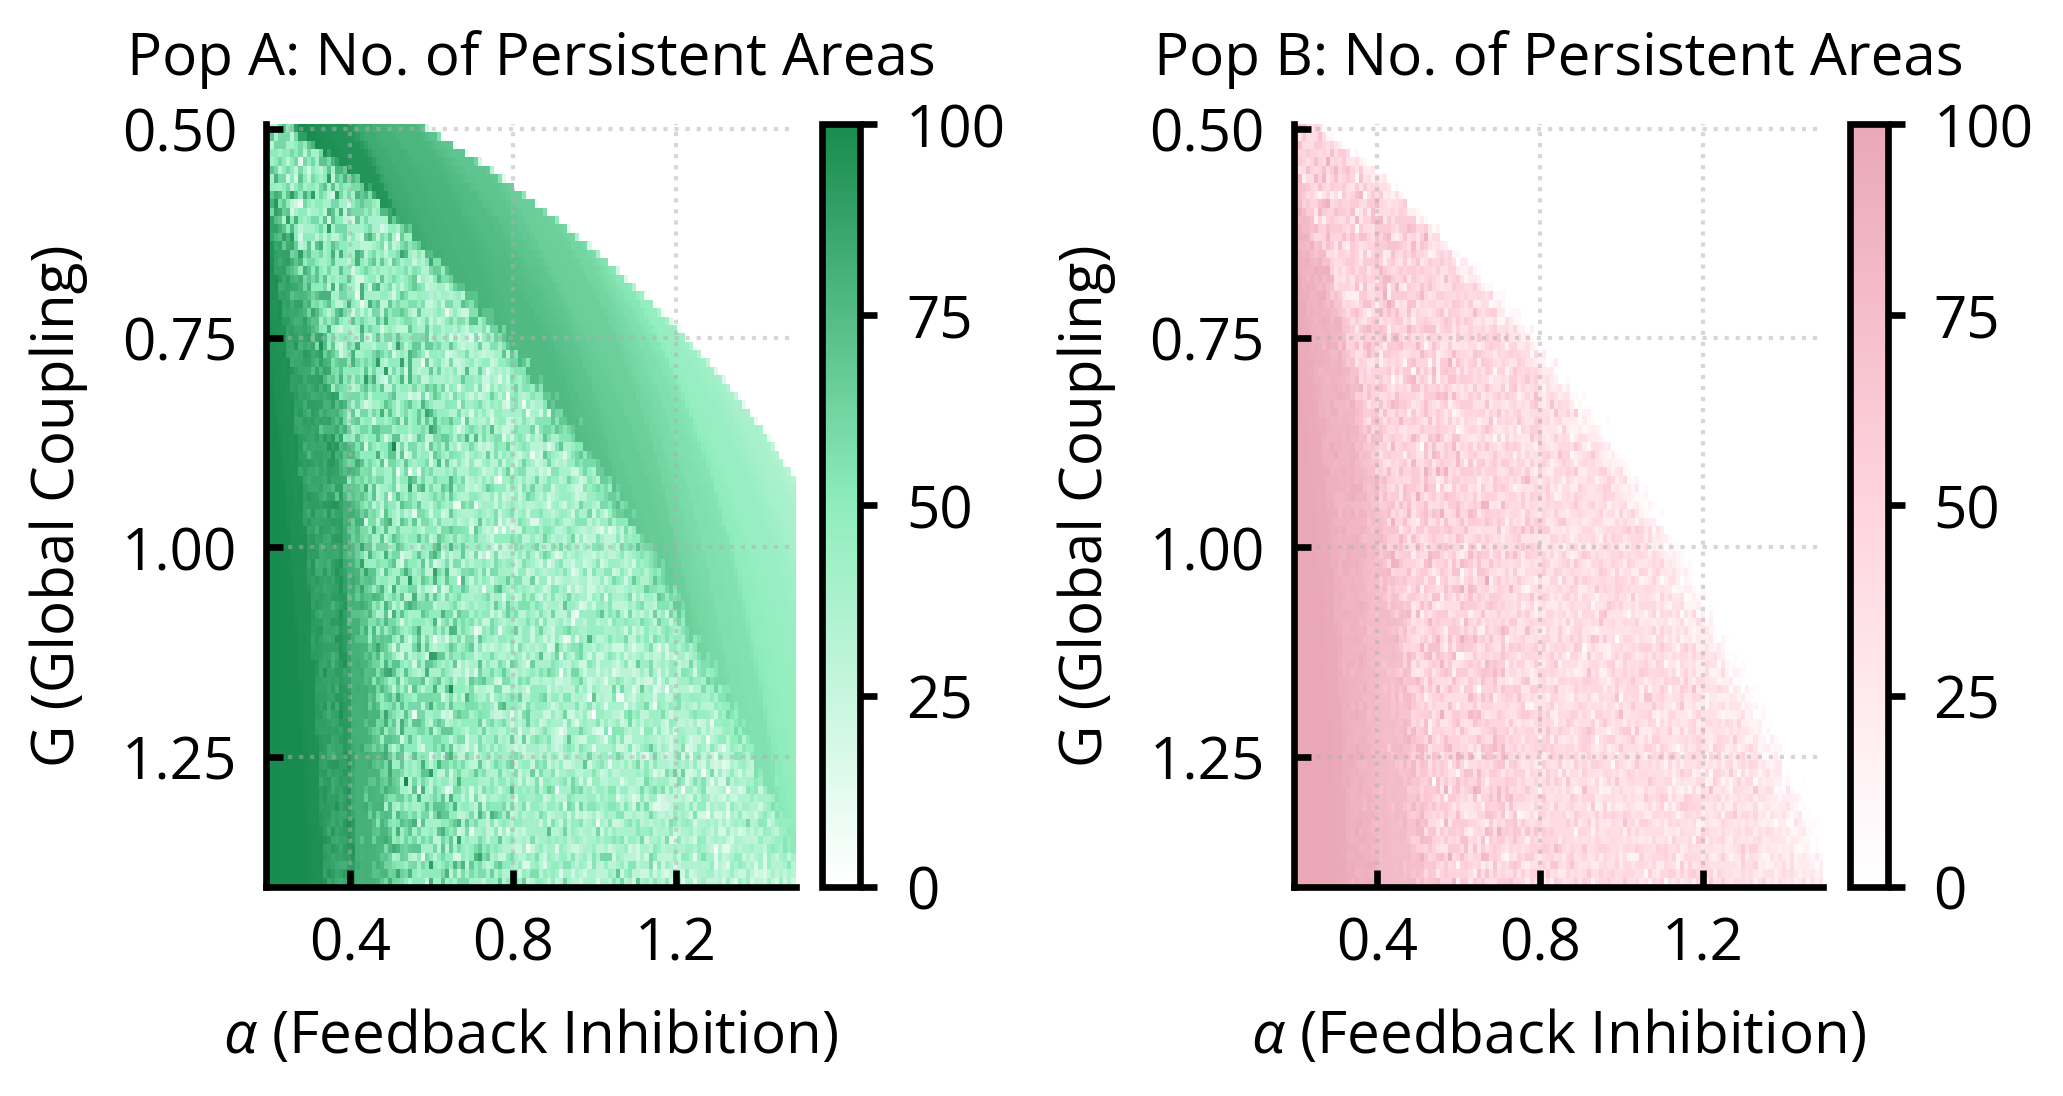

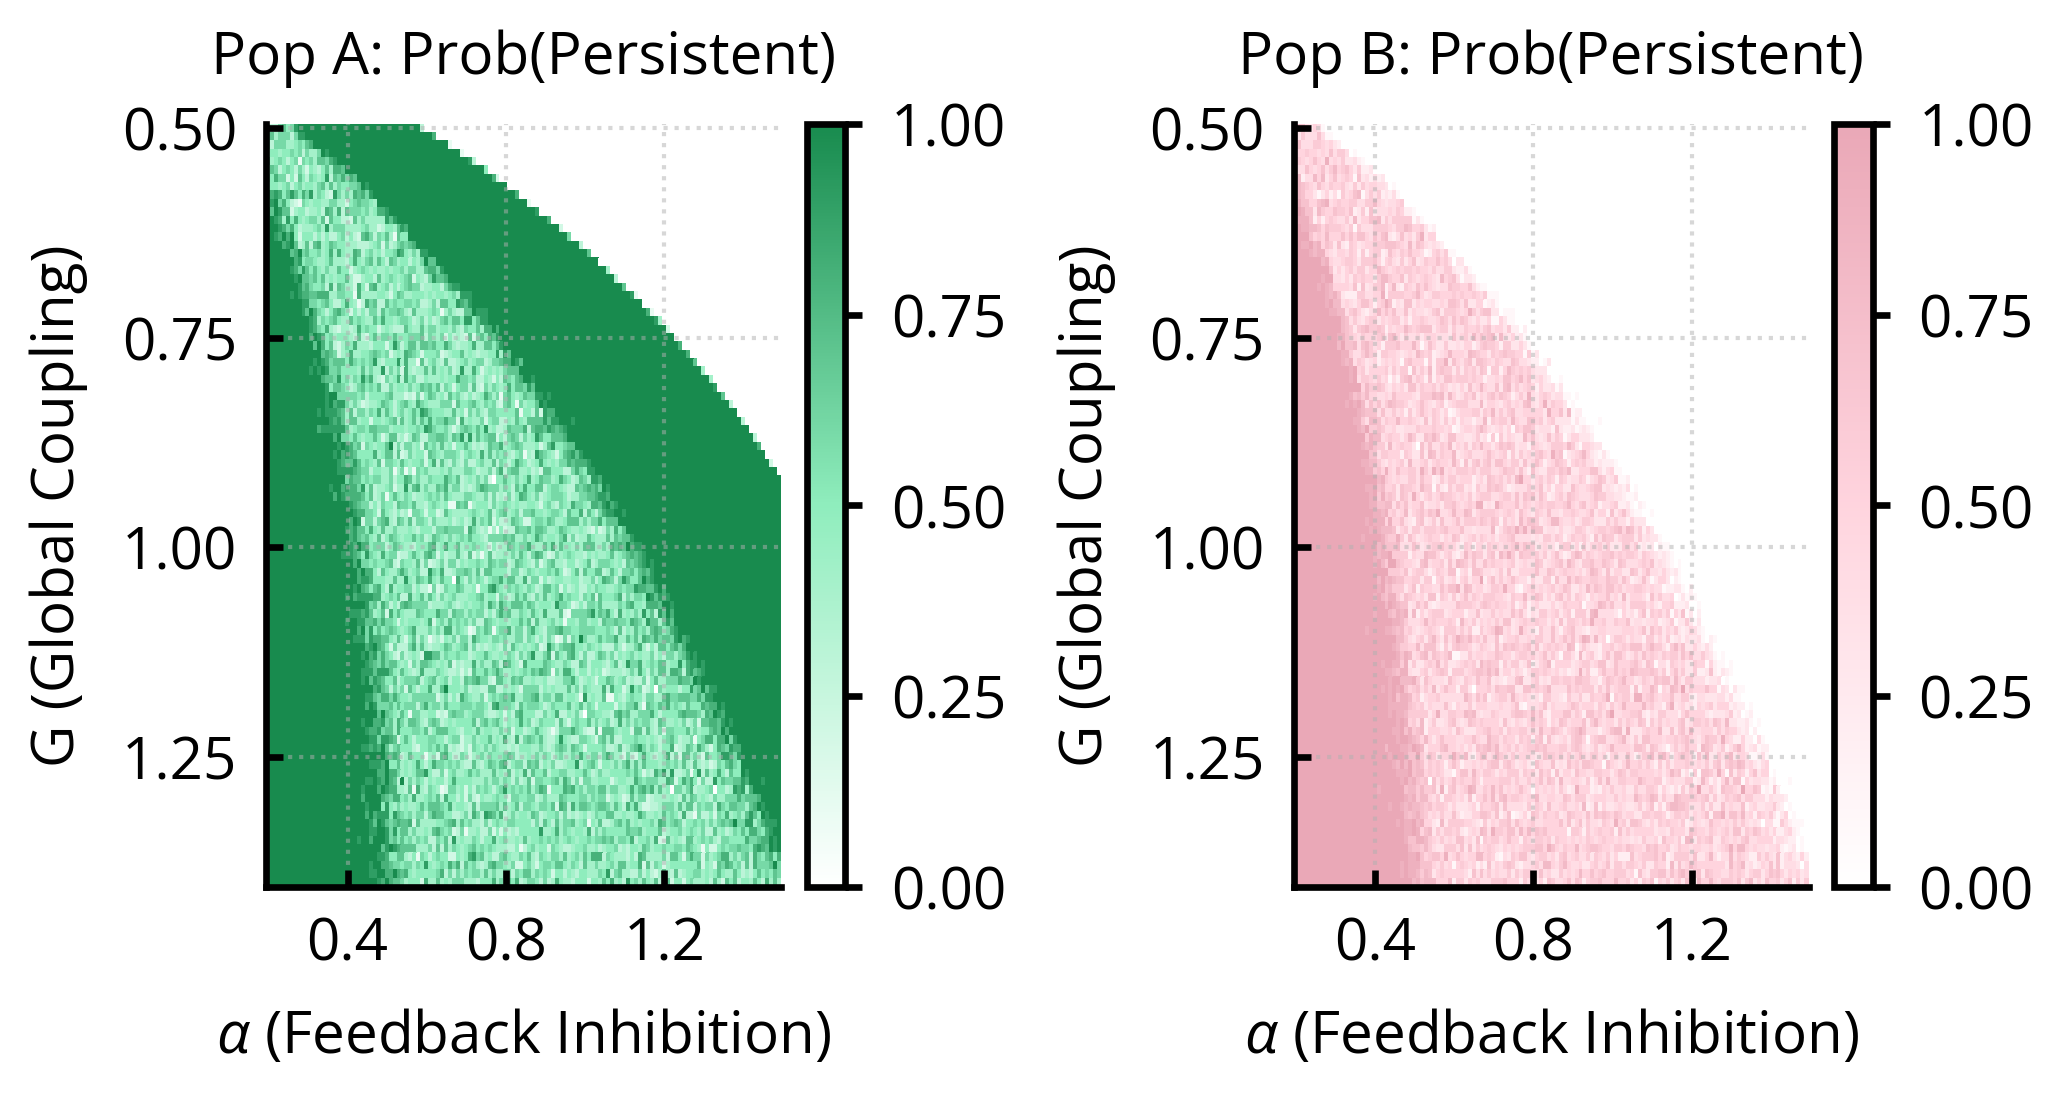

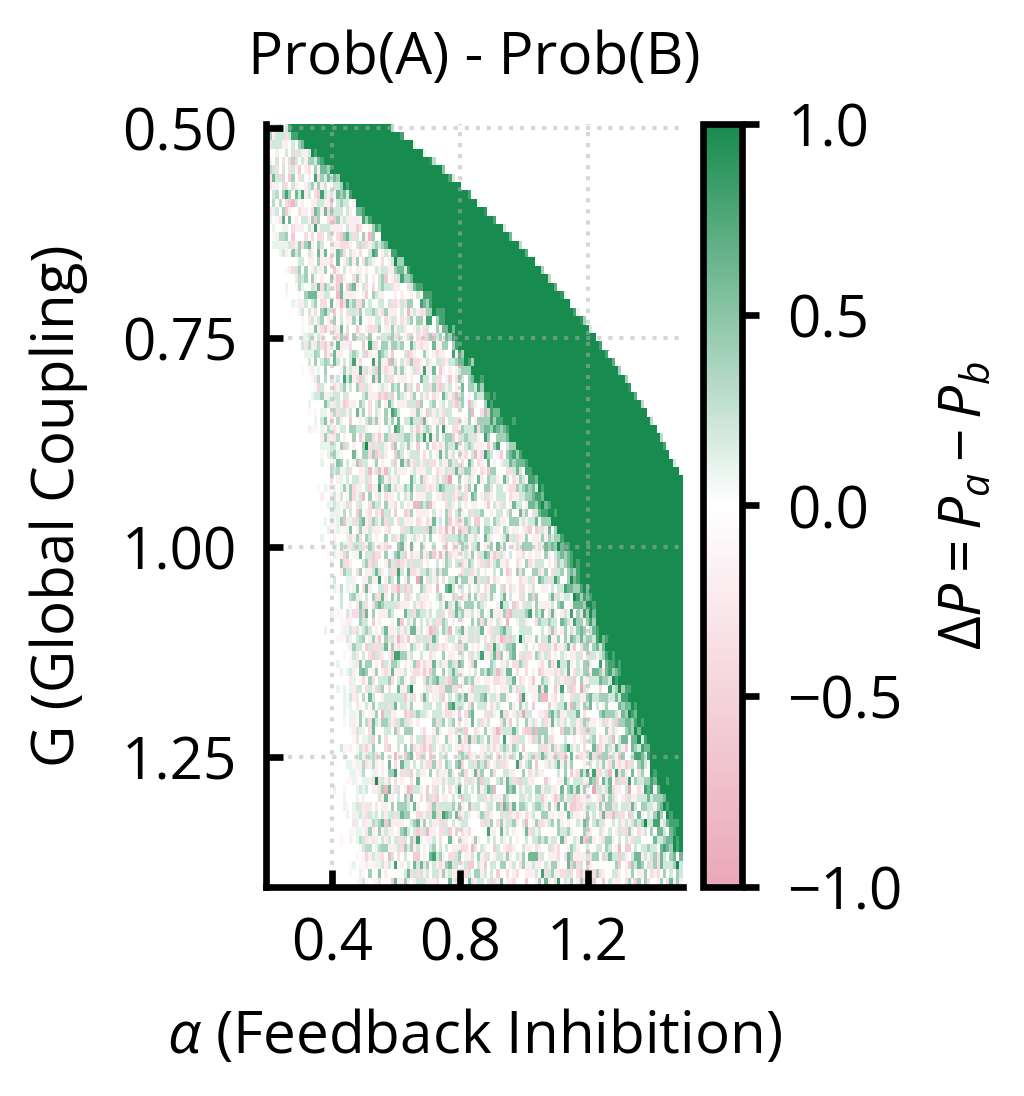

In [11]:
# Reads the same CSV as plot_forbidden_gap_analysis above
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Open Sans",
    "mathtext.it": "Open Sans:italic",
    "mathtext.bf": "Open Sans:bold",
    "mathtext.cal": "Open Sans:italic",
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
PAIR_W = (18.4 / 2 - 0.5) / CM  # half the page width, minus a margin
PAIR_H = 4.6 / CM
DIFF_W = (18.4 / 4 - 0.3) / CM  # a quarter of the page width, minus a margin
DIFF_H = 4.6 / CM
print(f'pair panel: {PAIR_W*CM:.2f} x {PAIR_H*CM:.2f} cm   diff panel: {DIFF_W*CM:.2f} x {DIFF_H*CM:.2f} cm')

# Same data and columns as plot_forbidden_gap_analysis
csv_path = '../models/model_pet_nmda/results/phase_diagram_G_alpha/g_alpha_random_seeds_per_G_alpha_corrected_spont_fun/persistent_activity_stats_all_runs.csv'
results_dir = 'saved_plots/Figure_4'
df = pd.read_csv(csv_path, delimiter=",", skipinitialspace=True)
df = df[df['G'] <= 1.4]  # Simulation didn't work for some values above this

df["Probability(A)"] = df["Prob_A_Only"] + df["Prob_A_B"]
df["Probability(B)"] = df["Prob_B_Only"] + df["Prob_A_B"]
df["ProbDiff(A-B)"] = df["Probability(A)"] - df["Probability(B)"]


def style_ax(ax, nbins=4):
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(nbins))
    ax.yaxis.set_major_locator(MaxNLocator(nbins))
    ax.grid(which='major', linestyle=':', alpha=0.5)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.tick_params(top=False, right=False)


def style_cbar(cbar, nbins=4):
    cbar.locator = MaxNLocator(nbins)
    cbar.update_ticks()
    cbar.ax.minorticks_off()
    cbar.ax.tick_params(which='both', direction='out', length=2, width=0.8)


def plot_pair(col_a, col_b, title_a, title_b, out_base):
    """The two Pop A / Pop B maps side by side in one 9.1 x 4.9 cm figure."""
    piv_a = df.pivot(index="G", columns="alpha", values=col_a)
    piv_b = df.pivot(index="G", columns="alpha", values=col_b)

    with mpl.rc_context(panel_style):
        # constrained_layout fits the colorbars without changing the figure size
        fig, axes = plt.subplots(1, 2, figsize=(PAIR_W, PAIR_H), constrained_layout=True)
        num = 0
        for ax, piv, title, cmap in zip(axes, [piv_a, piv_b], [title_a, title_b],
                                        [cmaps_phase['pop_A'], cmaps_phase['pop_B']]):
            im = ax.pcolor(piv.columns, piv.index, piv.values, cmap=cmap, shading='auto')
            ax.invert_yaxis()
            ax.set_title(title)
            ax.set_xlabel("$\\alpha$ (Feedback Inhibition)")
            ax.set_ylabel("G (Global Coupling)")
            style_ax(ax, nbins=4)
            style_cbar(fig.colorbar(im, ax=ax), nbins=4)

        # no bbox_inches='tight', so the file keeps the exact 9.1 x 4.9 cm size.
        fig.savefig(os.path.join(results_dir, f'{out_base}.pdf'))
        plt.show()


# 1. Number of persistent areas
plot_pair("MeanAreasA_uncond", "MeanAreasB_uncond",
          "Pop A: No. of Persistent Areas", "Pop B: No. of Persistent Areas",
          "mean_areas_AB_panel")

# 2. Probability of persistence
plot_pair("Probability(A)", "Probability(B)",
          "Pop A: Prob(Persistent)", "Pop B: Prob(Persistent)",
          "prob_A_vs_prob_B_panel")

# 3. Prob(A) - Prob(B), on its own at a quarter of the page width
piv_prob_diff = df.pivot(index="G", columns="alpha", values="ProbDiff(A-B)")
with mpl.rc_context(panel_style):
    fig, ax = plt.subplots(figsize=(DIFF_W, DIFF_H), constrained_layout=True)
    im = ax.pcolor(piv_prob_diff.columns, piv_prob_diff.index, piv_prob_diff.values,
                   cmap=cmaps_phase['pop_A_minus_B'], shading='auto')
    ax.invert_yaxis()
    ax.set_title("Prob(A) - Prob(B)")
    ax.set_xlabel("$\\alpha$ (Feedback Inhibition)")
    ax.set_ylabel("G (Global Coupling)")
    style_ax(ax, nbins=4)
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r'$\Delta P = P_a - P_b$')
    style_cbar(cbar, nbins=4)

    fig.savefig(os.path.join(results_dir, 'prob_diff_A_minus_B_panel.pdf'))
    plt.show()

### Small trace panel for the under-/over-active example

2.3 x 2.45 cm, half the width and height of the Prob(A) - Prob(B) panel, no axes.
Run the simulation cell above first.

trace panel: 2.15 x 2.30 cm


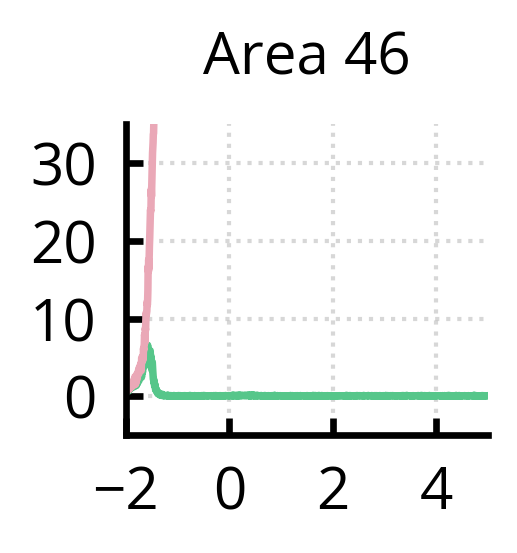

In [18]:
# Small trace panel for the under-active / over-active example, for the schematic.
# Half the width and half the height of the Prob(A) - Prob(B) panel: 2.3 x 2.45 cm.
# Styled like the plot_n_areas output above. Run the simulation cell above first;
# it plots whichever `experiment` that cell was last run with.
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

trace_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

# Same area and settings as the plot_n_areas call in the simulation cell
target_area_name = 'SalVentAttn_PFCl_1'  # 'Area 46'
variables = ['r_A', 'r_B']
colors = ['#56c68a', '#eaa8b7']
downsample = 10

# Same data plot_n_areas uses internally
state_history = WM_network.get_state_histories(variables)[-1]  # (n_timepoints, n_areas, n_variables)
t_down = WM_network.time_histories[-1][::downsample]
area_idx = np.where(np.array(WM_network.area_names) == target_area_name)[0][0]

# taken from the cell above, so this stays exactly half of the Prob(A) - Prob(B) panel
# even if DIFF_W / DIFF_H are retuned there
TRACE_W = DIFF_W / 2
TRACE_H = DIFF_H / 2
print(f'trace panel: {TRACE_W*CM:.2f} x {TRACE_H*CM:.2f} cm')

with mpl.rc_context(trace_style):
    fig, ax = plt.subplots(figsize=(TRACE_W, TRACE_H), constrained_layout=True)

    for var_idx, var in enumerate(variables):
        data = state_history[:, area_idx, var_idx][::downsample]
        # time is shifted so that 0 is the stimulus onset, as in plot_n_areas
        ax.plot(t_down - stim_start_time, data, color=colors[var_idx], linewidth=0.9)

    # same styling as plot_n_areas, at the smaller panel size
    ax.set_title(area_names_for_figure[0])
    ax.set_xlim(-2, t_end - 2)
    ax.set_ylim(-5, 35)   # same ylim as the plot_n_areas call above
    # ax.set_ylabel('Firing Rate (Hz)')
    # ax.set_xlabel('Time (s)')
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.grid(linestyle=':', alpha=0.5)

    # no bbox_inches='tight', so the file keeps the exact panel size printed above
    fig.savefig(f'saved_plots/Figure_4/{experiment}_persistent_activity_panel.svg')
    plt.show()